In [17]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from scipy.optimize import brute
%config InlineBackend.figure_format = "retina"

In [3]:
import warnings
warnings.filterwarnings(action = "ignore")

In [ ]:
class MACDBackTester():
    '''
    
    Attributes:
    ==========
    df: pd.DataFrame
        The dataframe of closing price that we would apply the trading strategy on it. 
        It must include the only one column (closing price), renamed "price".
    symbol: str
        The ticker that we want to trade.
    EMA_S: int
        Short term exponential moving average.
    EMA_L: int
        Long term exponential moving average.
    EMA_Signal:

    start: str
        The start date for the trading in YYYY-MM-DD format.
    end: str
        The end date for the trading in YYYY-MM-DD format.
    tc: float
        The trading cost for each trade (e.g. 0.001 = 0.1%)

    Methods:
    ========
    get_data():
    trading_strategy(displaying_mode = None):
    plot_results():
    set_parameters_update_strategy(new_EMA_S , new_EMA_L , new_MACD , displaying_mode = None):
    trading_strategy_optimization(EMA_S_range : (start , stop , step) , EMA_L_range : {start , stop , step))
    '''
    def __init__(self , df , symbol , EMA_S , EMA_L , EMA_Signal , start , end , tc):
        self.df = df
        self.symbol = symbol
        self.EMA_S = EMA_S
        self.EMA_L = EMA_L
        self.EMA_Signal = EMA_Signal
        self.start = start
        self.end = end
        self.tc = tc
        self.data = None
        self.results = None
        self.get_data()

    def __repr__(self) -> str:
        rep = f"MACD_BackTester(symbol : {self.symbol} | EMA_S : {self.EMA_S} | EMA_L : {self.EMA_L} | EMA_Sigmal : {self.EMA_Signal} | start : {self.start} | end : {self.end} | tc : {self.tc} )"
        return rep

    def get_data(self):
        '''Load the raw price data and compute initial EMAs'''
        raw = self.df.loc[self.start : self.end]
        # Calulate the EMAs:
        raw["EMA_S"] = raw["price"].ewm(span=self.EMA_S , min_periods=self.EMA_S).mean()
        raw["EMA_L"] = raw["price"].ewm(span = self.EMA_L , min_periods = self.EMA_L).mean()
        raw["MACD"] = raw["EMA_S"] - raw["EMA_L"]
        raw["MACD_Signal"] = raw["MACD"].ewm(span=self.EMA_Signal , min_periods=self.EMA_Signal).mean()
        self.data = raw
        return raw
    
    def trading_strategy(self , displaying_mode = None):
        '''
        Implement the trading strategy & displaying its performance in comparasion with the Buy & Hold strategy in term of a value or a dataframe.
        Paramters:
        ---------
        displaying_mode : str, optional
            'tabular' : returns styled KPI table.
            'value' : return single numeric value (last element of the cummulative return of the strategy).
        '''
        data = self.data.dropna()
        data["position"] = np.where(data["MACD"] > data["MACD_Signal"] , +1 , -1)
        data["trades"] = data["position"].diff().fillna(value = 0).abs()
        data["log_ret"] = np.log(data["price"]/data["price"].shift(1))
        data["strategy"] = data["position"].shift(1) * data["log_ret"] - data["trades"] * self.tc
        data["cum_log_ret"] = np.exp(data["log_ret"].cumsum()) #Buy & Hold Value
        data["cum_strategy"] = np.exp(data["strategy"].cumsum()) #Strategy Value
        data = data.dropna()
        self.results = data

        # Extract final performance values:
        strategy_performance =  data["cum_strategy"].iloc[-1]
        buy_and_hold_performance = data["cum_log_ret"].iloc[-1]
        out_performance = strategy_performance - buy_and_hold_performance

        self.KPI = pd.DataFrame(
            {   "Strategy" : strategy_performance ,
                "Buy & Hold" : buy_and_hold_performance ,
                "Out Performance" : out_performance ,
                "Ann. Return Buy & Hold" : data["log_ret"].mean() * 252 ,
                "Ann. Return Strategy" : data["strategy"].mean() *252 ,
                "Ann. Risk Buy & Hold" : np.sqrt(data["log_ret"].var() * 252) ,
                "Ann. Risk Strategy" : np.sqrt(data["strategy"].var() * 252)
            },
            index = ["EMA_S:{}| EMA_L:{}".format(self.EMA_S , self.EMA_L)]
        )
        self.KPI.index.name = "Performance"

        self.KPI_table = self.KPI.T.style.format("{:.2%}")
        if displaying_mode == "tabular":
            return self.KPI_table
        elif displaying_mode == "value":
            return float(strategy_performance)
        else:
            print("Display mode not specified.")
            return None

    def plot_results(self):
        '''Plot Strategy vs Buy & Hold'''
        fig , ax = plt.subplots(figsize = (14,6))
        data = self.results
        ax.plot(data.loc[: , 'MACD'] , color = "steelblue" , lw = 3 , label = 'MACD')
        ax.plot(data.loc[: , 'MACD_Signal'] , color = "orange" , lw = 3 , label = 'MACD_Signal')
        ax.set_title(f"EURUSD: MACD | MACD_Signal | Position \n EMA_S({self.EMA_S}) | EMA_L({self.EMA_L}) | EMA_Signal({self.EMA_Signal})" , fontsize = 18)
        ax.set_ylabel("Values" , fontsize = 14)
        ax.set_xlabel("Date" , fontsize = 14)
        ax.autoscale(enable=True , axis ="x" , tight = True)
        ax.legend(loc = (0,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
        fig.gca().spines[["right" , "top"]].set_visible(False)

        ax2 = ax.twinx()
        ax2.plot(data.loc[: , 'position'] , ls = ":" , color ="green" , lw = 2.5 , label = "position")
        ax2.autoscale(enable=True , axis ="x" , tight = True)
        ax2.set_ylabel("position" , color = "green" , fontsize =13)
        ax2.set_yticks(ticks =  [-1 , +1] , 
                labels = ['-1: Short' , '+1: Long'] , color = "green")
        ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")

        plt.gca().spines[["right" , "top"]].set_visible(False)
        plt.grid(axis ="y")
        plt.tight_layout()
        plt.show()

    def set_parameters(self , new_EMA_S , new_EMA_L , new_EMA_Signal):
        '''update the new EMA_S & EMA_L parameters and recalculate the MACD , MACD_Signal on the existing data.
        '''
        if self.data is None or self.data.empty:
            raise AttributeError("Data not Loaded. Call get_data() first.")
        new_raw = self.data[["price"]].copy()
        if new_EMA_S is not None:
            self.EMA_S = int(new_EMA_S)
        if new_EMA_L is not None:
            self.EMA_L = int(new_EMA_L)
        if new_EMA_Signal is not None:
            self.EMA_Signal = int(new_EMA_Signal)

        new_raw["EMA_S"] = new_raw["price"].ewm(span=self.EMA_S , min_periods=self.EMA_S).mean()
        new_raw["EMA_L"] = new_raw["price"].ewm(span = self.EMA_L , min_periods = self.EMA_L).mean()
        new_raw["MACD"] = new_raw["EMA_S"] - new_raw["EMA_L"]
        new_raw["MACD_Signal"] = new_raw["MACD"].ewm(span=self.EMA_Signal , min_periods=self.EMA_Signal).mean()
        self.data = new_raw   

    def optimized_trading_strategy(self , EMA_S_range : tuple , EMA_L_range : tuple , EMA_Signal_range : tuple):
        '''Finding the optimal values for the parameters EMA_S, EMA_L, EMA_Signal to maximize the strategy's return value.
        Parameters:
        ===========
        EMA_S_range = (start , stop , step)
        EMA_L_range = (start , stop , step)
        EMA_Signal = (start , stop , step)

        Returns:
        ========
        best_parameters: ndarray
            Array [EMA_S , EMA_L , EMA_Signal] foe the best EMA_S , EMA_L , and EMA_Signal
        best_strategy: DataFrame/Style
            DataFrame/Style
        '''
        
        def objective_function(x):
            self.set_parameters(x[0],x[1],x[2])
            return -1 * self.trading_strategy(displaying_mode="value")
        
        print("starting optimization ... This may take  time depending on the range size.")
        res = brute(objective_function , ranges = (EMA_S_range , EMA_L_range , EMA_Signal_range))
        best_EMA_S = res[0]
        best_EMA_L = res[1]
        best_EMA_Signal = res[2]
        print(f"Optimal Parameters found : EMA_S {best_EMA_S} | EMA_L {best_EMA_L} | EMA_Signal {best_EMA_Signal}")
        self.set_parameters(new_EMA_S = best_EMA_S , new_EMA_L = best_EMA_L , new_EMA_Signal = best_EMA_Signal)
        
        
        return self.trading_strategy(displaying_mode="tabular")

In [34]:
symbol = "EURUSD=X"
df = pd.read_csv("forex_pairs.csv" , index_col=["Date"] , parse_dates=["Date"])
df = df.loc[: , symbol].to_frame()
df.columns = ["price"]

start = "2004-01-01"
end = "2020-06-03"

pct = 0.00005

In [35]:
macd = MACDBackTester(df , symbol = symbol , EMA_S = 12 , EMA_L = 26 , EMA_Signal = 9 , start = start , end = end , tc = pct)
macd

MACD_BackTester(symbol : EURUSD=X | EMA_S : 12 | EMA_L : 26 | EMA_Sigmal : 9 | start : 2004-01-01 | end : 2020-06-03 | tc : 5e-05 )

In [36]:
df

,price
Date,
2004-01-01,1.258194
2004-01-02,1.258194
2004-01-05,1.268698
2004-01-06,1.272103
2004-01-07,1.264095
...,...
2020-06-24,1.131235
2020-06-25,1.125087
2020-06-26,1.122208


In [37]:
macd.get_data()

,price,EMA_S,EMA_L,MACD,MACD_Signal
Date,,,,,
2004-01-01,1.258194,NaN,NaN,NaN,NaN
2004-01-02,1.258194,NaN,NaN,NaN,NaN
2004-01-05,1.268698,NaN,NaN,NaN,NaN
2004-01-06,1.272103,NaN,NaN,NaN,NaN
2004-01-07,1.264095,NaN,NaN,NaN,NaN
...,...,...,...,...,...
2020-05-28,1.101686,1.092518,1.090299,0.002219,0.000437
2020-05-29,1.107911,1.094886,1.091604,0.003283,0.001006
2020-06-01,1.111852,1.097497,1.093104,0.004393,0.001684


In [39]:
macd.trading_strategy(displaying_mode="tabular")

Performance,EMA_S:12| EMA_L:26
Strategy,42.48%
Buy & Hold,87.02%
Out Performance,-44.54%
Ann. Return Buy & Hold,-0.83%
Ann. Return Strategy,-5.11%
Ann. Risk Buy & Hold,12.06%
Ann. Risk Strategy,12.07%


In [40]:
macd.results

,price,EMA_S,EMA_L,MACD,MACD_Signal,position,trades,log_ret,strategy,cum_log_ret,cum_strategy
Date,,,,,,,,,,,
2004-02-18,1.272508,1.271449,1.266693,0.004756,0.003408,1,0.0,-0.010386,-0.010386,0.989667,0.989667
2004-02-19,1.275705,1.272106,1.267405,0.004700,0.003691,1,0.0,0.002510,0.002510,0.992154,0.992154
2004-02-20,1.254202,1.269345,1.266367,0.002978,0.003538,-1,2.0,-0.017000,-0.017100,0.975430,0.975333
2004-02-23,1.257197,1.267473,1.265649,0.001824,0.003175,-1,0.0,0.002386,-0.002386,0.977760,0.973008
2004-02-24,1.267797,1.267523,1.265817,0.001706,0.002868,-1,0.0,0.008395,-0.008395,0.986003,0.964874
...,...,...,...,...,...,...,...,...,...,...,...
2020-05-28,1.101686,1.092518,1.090299,0.002219,0.000437,1,0.0,0.003190,0.003190,0.856814,0.418259
2020-05-29,1.107911,1.094886,1.091604,0.003283,0.001006,1,0.0,0.005635,0.005635,0.861655,0.420623
2020-06-01,1.111852,1.097497,1.093104,0.004393,0.001684,1,0.0,0.003552,0.003552,0.864721,0.422119


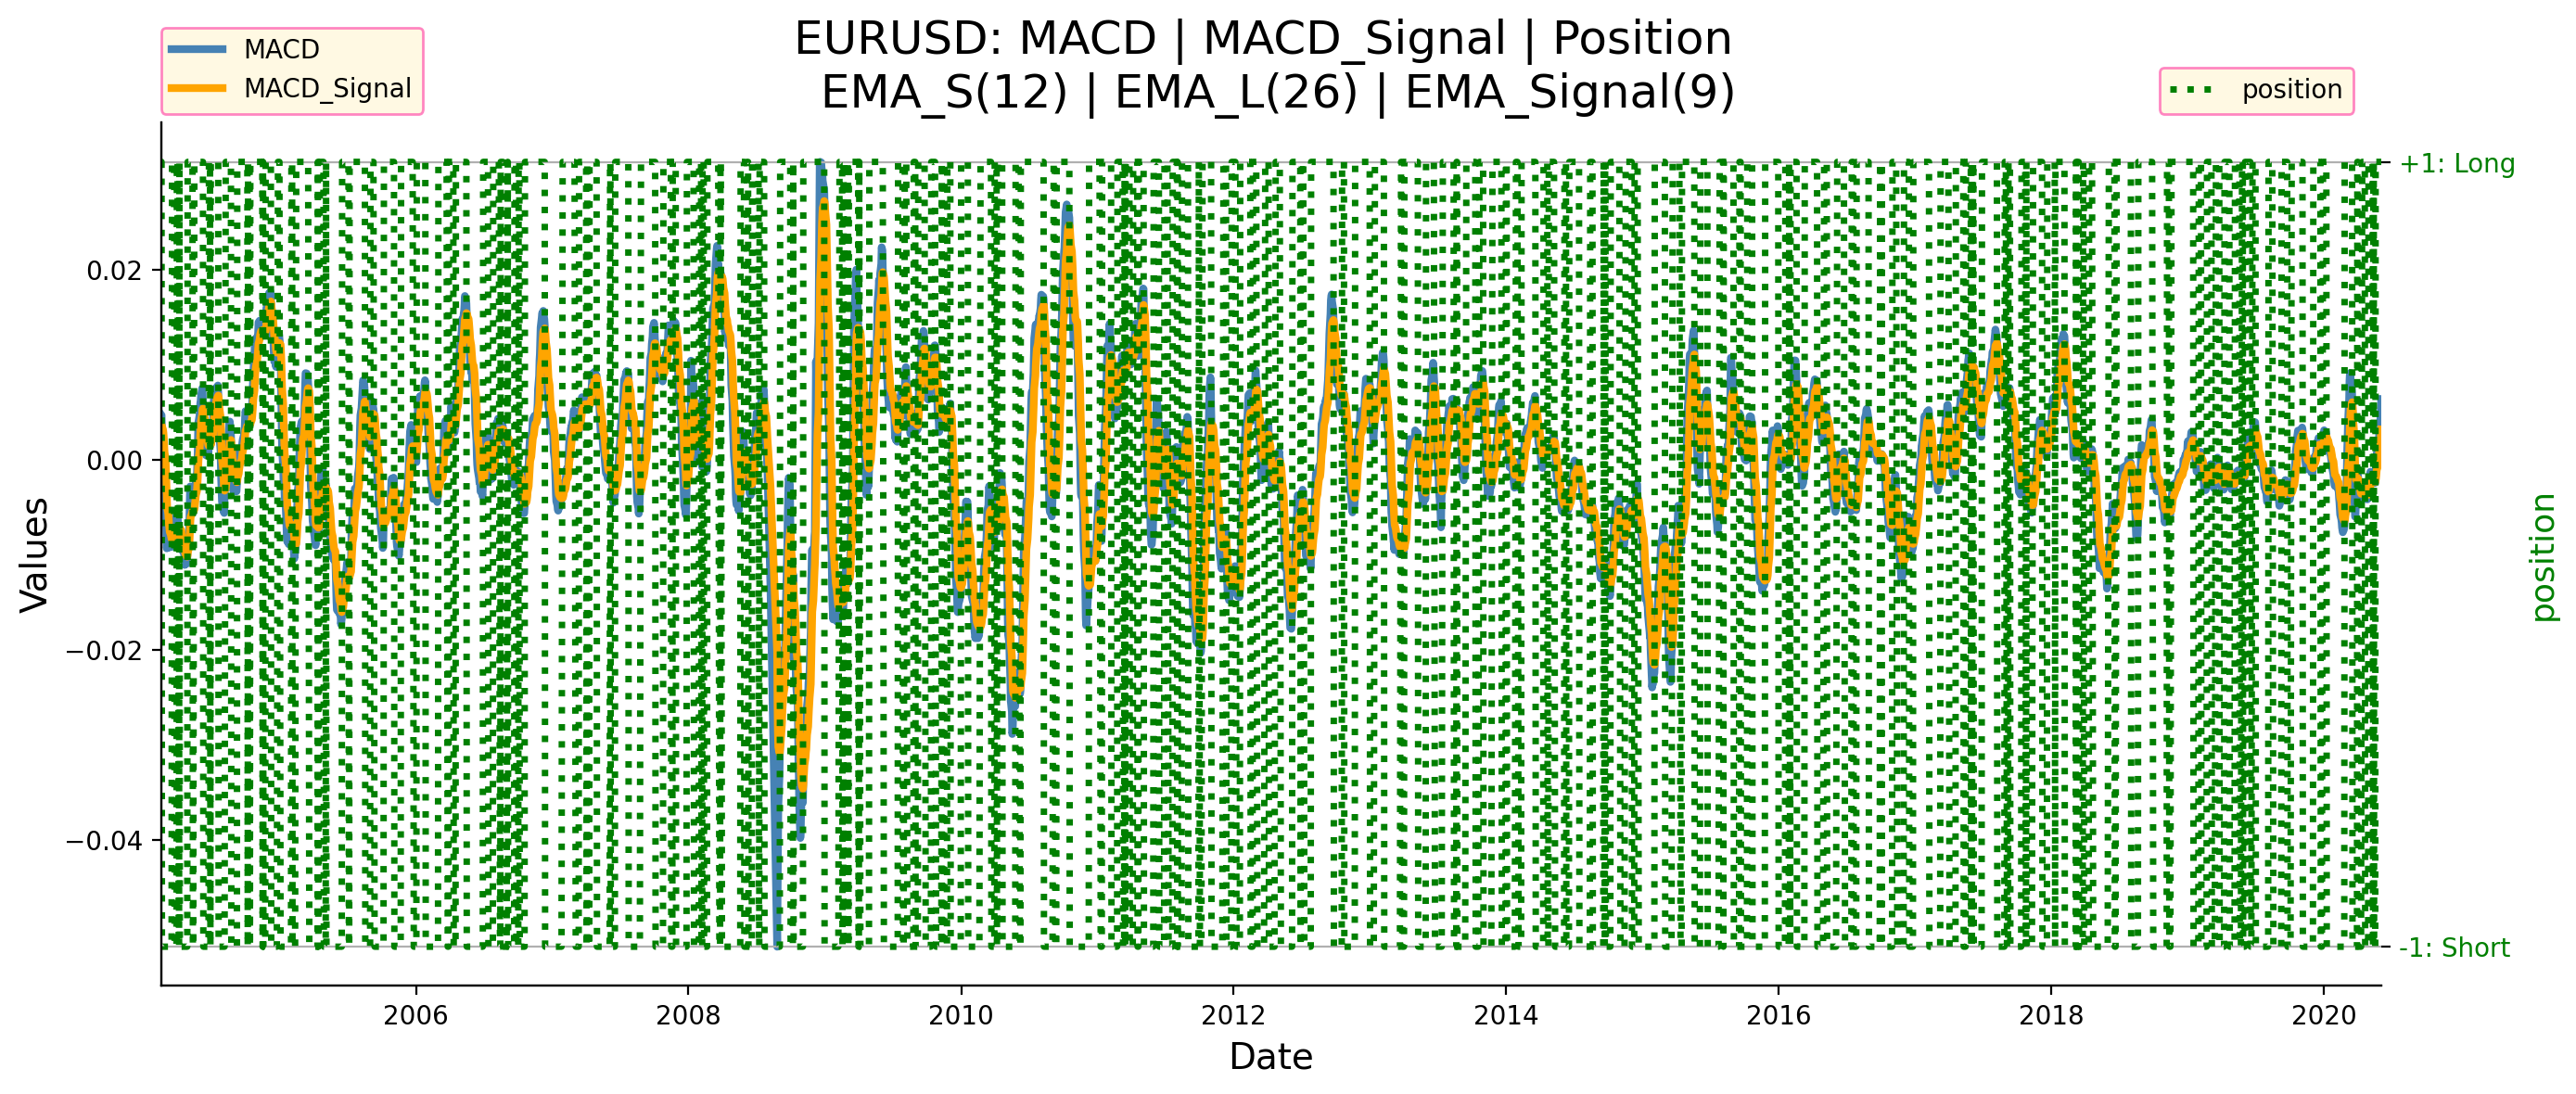

In [41]:
macd.plot_results()

In [42]:
macd_df = macd.results
macd_df

,price,EMA_S,EMA_L,MACD,MACD_Signal,position,trades,log_ret,strategy,cum_log_ret,cum_strategy
Date,,,,,,,,,,,
2004-02-18,1.272508,1.271449,1.266693,0.004756,0.003408,1,0.0,-0.010386,-0.010386,0.989667,0.989667
2004-02-19,1.275705,1.272106,1.267405,0.004700,0.003691,1,0.0,0.002510,0.002510,0.992154,0.992154
2004-02-20,1.254202,1.269345,1.266367,0.002978,0.003538,-1,2.0,-0.017000,-0.017100,0.975430,0.975333
2004-02-23,1.257197,1.267473,1.265649,0.001824,0.003175,-1,0.0,0.002386,-0.002386,0.977760,0.973008
2004-02-24,1.267797,1.267523,1.265817,0.001706,0.002868,-1,0.0,0.008395,-0.008395,0.986003,0.964874
...,...,...,...,...,...,...,...,...,...,...,...
2020-05-28,1.101686,1.092518,1.090299,0.002219,0.000437,1,0.0,0.003190,0.003190,0.856814,0.418259
2020-05-29,1.107911,1.094886,1.091604,0.003283,0.001006,1,0.0,0.005635,0.005635,0.861655,0.420623
2020-06-01,1.111852,1.097497,1.093104,0.004393,0.001684,1,0.0,0.003552,0.003552,0.864721,0.422119


In [43]:
class RSIBackTester():
    '''
    It is a trading strategy implemented based on the RSI (Relative Strength Index).
    Attributes:
    ===========
    df: pd.DataFrame
        The dataframe of closing price that we would apply the trading strategy on it. 
        It must include the only one column (closing price), renamed "price".
    symbol: str
        Instrument ticker.
    periods: int
        It is the period to compute the moving average for both of the UpTrend & DownTrend.
    rsi_upper: int:
        Upper threshold for selling signals.
    rsi_lower: int:
        Lower threshold for buying signals.
    start: str
        Backtest start date, format : 'YYYY-MM-DD'
    end: str
        backtest end date. format: 'YYYY-MM-DD'
    tc: float
        Transaction cost per trade(fractional, e.g., 0.001 = 0.1%).
    Methods:
    ========
    get_data()
    trading_strategy(displaying_mode = None):
    set_parameters(new_periods , new_rsi_upper , new_rsi_lower)
    optimized_trading_strategy(new_periods_range : (start , stop , step) , new_upper_rsi_range : (start , stop , step) , new_lower_rsi_range : (start , stop , step))
    plot_results() 
    '''
    def __init__(self , df , symbol , periods , rsi_upper , rsi_lower , start , end , tc):
        self.df = df
        self.symbol = symbol
        self.periods = periods
        self.rsi_upper = rsi_upper
        self.rsi_lower = rsi_lower
        self.start = start
        self.end = end
        self.tc = tc
        self.get_data()
        self.results = None
        self.KPI = None
        self.KPI_table = None

    def __repr__(self):
        rep = f"RSI_BackTester(Symbol : {self.symbol} | periods : {self.periods} | RSI_Thresh0 : ({self.rsi_upper} , {self.rsi_lower}) | start : {self.start} | end : {self.end} | pct : {self.tc})"
        return rep

    def get_data(self):
        '''Load the raw data and compute the RSI and its related components. '''
        raw = self.df.loc[self.start:self.end]
        raw["UP"] = np.where(raw["price"].diff() > 0 , raw["price"].diff() , 0)
        raw["Down"] = np.where(raw["price"].diff() < 0 , -raw["price"].diff() , 0)
        raw["MA_UP"] = raw["UP"].rolling(window = self.periods).mean()
        raw["MA_Down"] = raw["Down"].rolling(window = self.periods).mean()
        raw["RSI"] = raw["MA_UP"] / (raw["MA_UP"] + raw["MA_Down"])
        raw["RSI"] = raw["RSI"] * 100
        raw = raw.dropna()
        self.data = raw
        return raw

    def trading_strategy(self , displaying_mode = None):
        '''
        Implement the RSI trading strategy & displaying its performance in comparasion with the buy&hold strategy.
        Parameters:
        ===========
        displaying_mode : str , optional
            'tabular' : returns styled KPI table.
            'value' : return the single value: the performance of our trading strategy.
        '''
        data = self.data
        data["position"] = np.where(data["RSI"]>self.rsi_upper , -1 , np.where(data["RSI"]<self.rsi_lower , +1 , 0))
        data["trades"] = data["position"].diff().fillna(0).abs()
        data["log_ret"] = np.log(data["price"]/data["price"].shift(1))
        data["strategy"] = data["position"].shift(1) * data["log_ret"]
        data["strategy_net"] = data["position"].shift(1) * data["log_ret"] - data["trades"] * self.tc
        data["cum_ret"] = np.exp(data["log_ret"].cumsum())
        data["cum_strategy"] = np.exp(data["strategy"].cumsum())
        data["cum_strategy_net"] = np.exp(data["strategy_net"].cumsum())
        data = data.dropna()
        self.results = data

        # Extract final performance values:
        strategy_performance = data["cum_strategy_net"].iloc[-1]
        buy_and_hold_performance = data["cum_ret"].iloc[-1]
        out_performance = strategy_performance - buy_and_hold_performance

        self.KPI = pd.DataFrame(
            {"Strategy" : strategy_performance ,
            "Buy & Hold" : buy_and_hold_performance ,
            "Out Performance" : out_performance,
            "Ann. Return Buy & Hold" : data["log_ret"].mean() * 252,
            "Ann. Return Strategy" : data["strategy_net"].mean() * 252,
            "Ann. Risk Buy & Hold" : np.sqrt(data["log_ret"].var() * 252),
            "Ann. Risk Strategy" : np.sqrt(data["strategy_net"].var() * 252),
            } , 
            index = [f"RSI_Upper:{self.rsi_upper} | RSI_Lower:{self.rsi_lower}"]
        )

        self.KPI.index.name = "Performance"

        self.KPI_table = self.KPI.T.style.format("{:.2%}")

        if displaying_mode == "tabular":
            return self.KPI_table
        
        elif displaying_mode == "value":
            return float(strategy_performance)
        
        else:
            print("Display mode not specified.")
            return None

    def plot_results(self):
        '''Plot the RSI trading strategy performance vs the buy&hold strategy.'''
        fig , ax = plt.subplots(figsize = (12,6))
        data = self.results
        ax.plot(data.loc[:, ["cum_ret"]] , label = "Buy&Hold Strategy" , lw = 2 , alpha = .6)
        ax.plot(data.loc[:, ["cum_strategy"]] , label = "RSI Trading Strategy" , lw = 2 ,color ="orange", alpha = .6)
        ax.plot(data.loc[:, ["cum_strategy_net"]] , label = "RSI Net Trading Strategy" , lw = 2 ,color ="cyan", alpha = .9)
        ax.spines[["right" , "top"]].set_visible(False)
        ax.legend(loc = (0.,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
        ax.autoscale(enable=True , axis ="x" , tight = True)
        ax.set_xlabel("Date" , fontsize = 13)
        ax.set_title(f"{self.symbol}: RSI | Price" , fontsize = 18)
        ax.grid(ls = ":", lw= .8)

        ax2 = ax.twinx()
        ax2.plot(data.loc[:, ["RSI"]] , label = "RSI" , color = "gray" , ls ="--" , lw = 2 , alpha = 0.6)
        ax2.spines[["right" , "top"]].set_visible(False)
        ax2.autoscale(enable=True , axis ="x" , tight = True)
        ax2.axhline(y=self.rsi_upper , color = "red" , label = f"RSI > {self.rsi_upper} : Selling Signal" , lw = 3)
        ax2.axhline(y=self.rsi_lower , color = "green" , label = f"RSI < {self.rsi_lower} : Buying Signal" , lw = 3)
        ax2.legend(loc = (0.9,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
        ax2.set_yticks(ticks = [self.rsi_lower,self.rsi_upper])
        ax2.set_yticklabels(labels = ["Buying" , "Selling"])
        for label in ax2.get_yticklabels():
            if label.get_text() == "Buying":
                label.set_color("green")
            elif label.get_text() == "Selling":
                label.set_color("red")

        plt.tight_layout()
        plt.show()

    def set_parameter(self, new_periods = None , new_rsi_upper = None , new_rsi_lower = None):
        '''
        update the new periods, new_rsi_upper, and the new_rsi_lower parameters and recalculate the : UP, DoWN,MA_UP ,MA_Down,RSI.
        '''
        if self.data is None or self.data.empty:
            raise AttributeError("Data not loaded. Call get_data() first.")
        new_raw = self.df.loc[self.start:self.end]
        if new_periods is not None:
            self.periods = int(new_periods)
        if new_rsi_upper is not None:
            self.rsi_upper = int(new_rsi_upper)
        if new_rsi_lower is not None:
            self.rsi_lower = int(new_rsi_lower)

        new_raw = self.df.loc[self.start:self.end]
        new_raw["UP"] = np.where(new_raw["price"].diff() > 0 , new_raw["price"].diff(), 0)
        new_raw["Down"] = np.where(new_raw["price"].diff() < 0 , -new_raw["price"].diff() , 0)
        new_raw["MA_UP"] = new_raw["UP"].rolling(window = self.periods).mean()
        new_raw["MA_Down"] = new_raw["Down"].rolling(window = self.periods).mean()
        new_raw["RSI"] = new_raw["MA_UP"] / (new_raw["MA_UP"] + new_raw["MA_Down"])
        new_raw["RSI"] = new_raw["RSI"] * 100
        new_raw = new_raw.dropna()
        self.data = new_raw
        return new_raw

    def optimized_trading_strategy(self, periods_range:tuple , rsi_upper_ranges:tuple , rsi_lower_range:tuple):
        '''
        grid search algorithm using the brute function to find the maximum value of the strategy return.
        Parameters:
        ===========
        periods_range: (start , stop , step)
            it is a range for the periods.

        rsi_upper_ranges: (start , stop , step)
            it is a range to find the best value of the RSI upper threshold.

        rsi_lower_range: (start , stop , step)
            it is the range to find the bes value of the RSI lower threshold.
        
        Returns:
        ========
        best_parameters: ndarray
            Array [periods , rsi_upper , rsi_lower] for the best periods , rsi_upper , rsi_lower.
        best_strategy: DataFrame/Style
        '''

        def objective_function(x):
            self.set_parameter(x[0] , x[1] , x[2])
            values = self.trading_strategy(displaying_mode="value")
            return -values

        print("starting optimization ... This may take time depending on the range size.")
        res = brute(objective_function , ranges = (periods_range , rsi_upper_ranges , rsi_lower_range))
        best_periods = res[0]
        best_rsi_upper = res[1]
        best_rsi_lower = res[2]
        print(f"Optimal Parameters found : periods {best_periods} | best Upper_RSI : {best_rsi_upper} | best Lower_RSI : {best_rsi_lower}")
        self.set_parameter(new_periods=best_periods , new_rsi_upper=best_rsi_upper , new_rsi_lower=best_rsi_lower)
        
        
        return self.trading_strategy(displaying_mode="tabular")

In [44]:
rsi = RSIBackTester(df ,symbol = symbol , start = start , end = end , periods=20 , rsi_lower=30 , rsi_upper=70 , tc= pct)
rsi

RSI_BackTester(Symbol : EURUSD=X | periods : 20 | RSI_Thresh0 : (70 , 30) | start : 2004-01-01 | end : 2020-06-03 | pct : 5e-05)

In [45]:
rsi.get_data()

,price,UP,Down,MA_UP,MA_Down,RSI
Date,,,,,,
2004-01-28,1.244199,0.000000,0.019496,0.004610,0.005310,46.472973
2004-01-29,1.241003,0.000000,0.003196,0.004610,0.005470,45.736150
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086
...,...,...,...,...,...,...
2020-05-28,1.101686,0.003508,0.000000,0.002253,0.001555,59.164735
2020-05-29,1.107911,0.006225,0.000000,0.002223,0.001555,58.842191
2020-06-01,1.111852,0.003942,0.000000,0.002350,0.001555,60.173623


In [46]:
rsi.trading_strategy(displaying_mode="tabular")

Performance,RSI_Upper:70 | RSI_Lower:30
Strategy,152.51%
Buy & Hold,89.93%
Out Performance,62.58%
Ann. Return Buy & Hold,-0.63%
Ann. Return Strategy,2.51%
Ann. Risk Buy & Hold,12.05%
Ann. Risk Strategy,5.48%


In [47]:
rsi_df = rsi.results
rsi_df

,price,UP,Down,MA_UP,MA_Down,RSI,position,trades,log_ret,strategy,strategy_net,cum_ret,cum_strategy,cum_strategy_net
Date,,,,,,,,,,,,,,
2004-01-29,1.241003,0.000000,0.003196,0.004610,0.005470,45.736150,0,0.0,-0.002572,-0.0,-0.00000,0.997431,1.000000,1.000000
2004-01-30,1.246805,0.005802,0.000000,0.004900,0.005470,47.254310,0,0.0,0.004665,0.0,0.00000,1.002095,1.000000,1.000000
2004-02-02,1.243302,0.000000,0.003503,0.004375,0.005645,43.663573,0,0.0,-0.002814,-0.0,-0.00000,0.999279,1.000000,1.000000
2004-02-03,1.253494,0.010192,0.000000,0.004714,0.005645,45.509086,0,0.0,0.008164,0.0,0.00000,1.007471,1.000000,1.000000
2004-02-04,1.253997,0.000503,0.000000,0.004740,0.005244,47.471521,0,0.0,0.000401,0.0,0.00000,1.007875,1.000000,1.000000
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
2020-05-28,1.101686,0.003508,0.000000,0.002253,0.001555,59.164735,0,0.0,0.003190,0.0,0.00000,0.885458,1.550127,1.525218
2020-05-29,1.107911,0.006225,0.000000,0.002223,0.001555,58.842191,0,0.0,0.005635,0.0,0.00000,0.890461,1.550127,1.525218
2020-06-01,1.111852,0.003942,0.000000,0.002350,0.001555,60.173623,0,0.0,0.003552,0.0,0.00000,0.893629,1.550127,1.525218


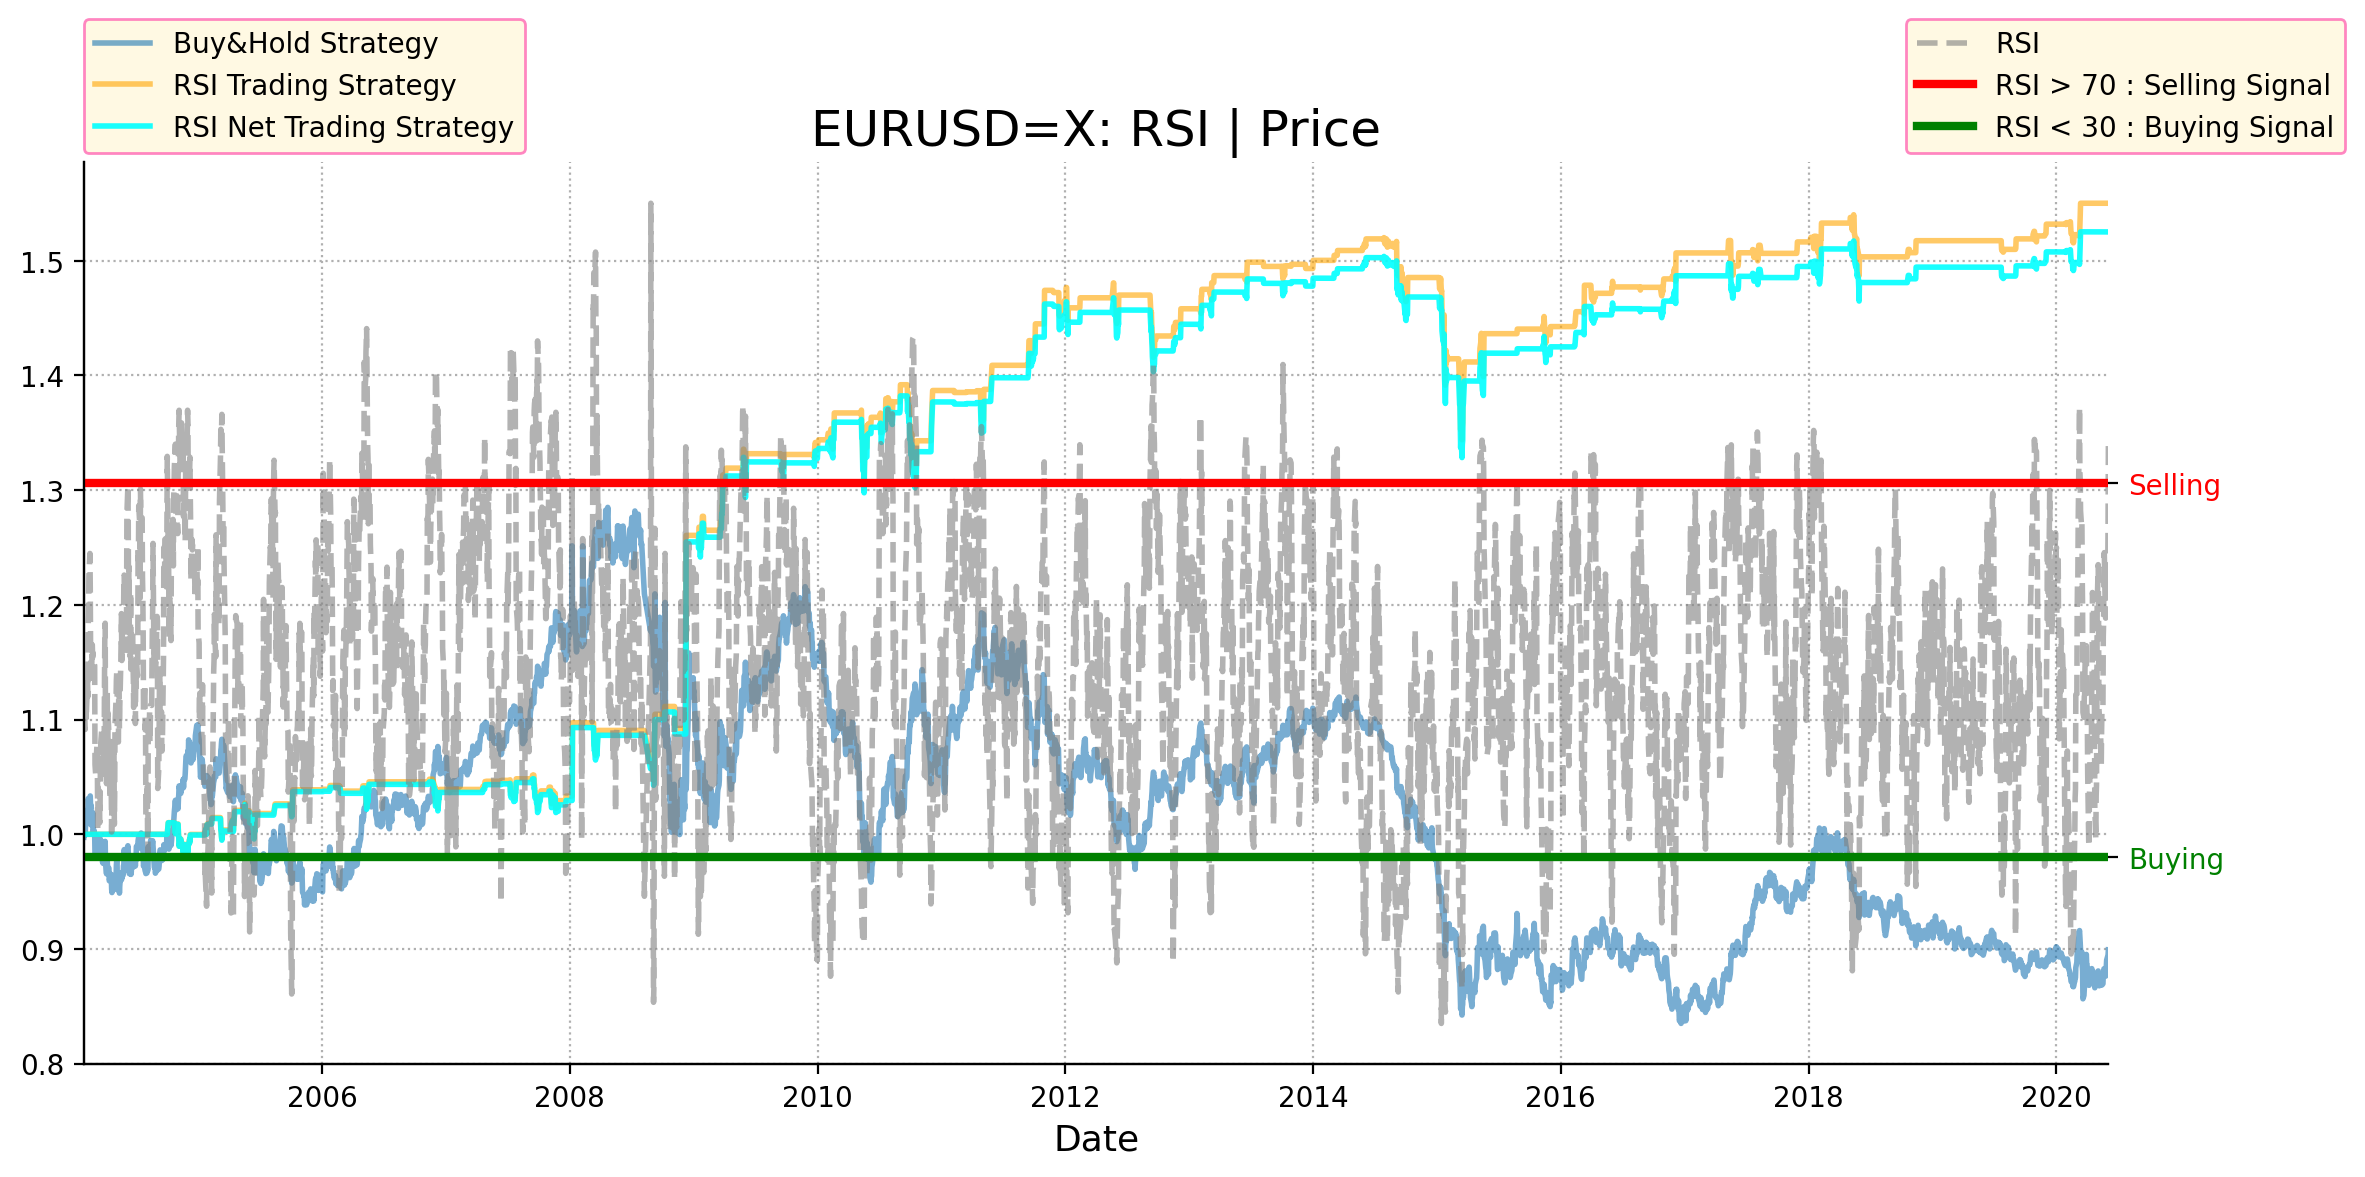

In [48]:
rsi.plot_results()

##### MACD & RSI combination strategy:

In [49]:
macd_df.columns

Index(['price', 'EMA_S', 'EMA_L', 'MACD', 'MACD_Signal', 'position', 'trades',
       'log_ret', 'strategy', 'cum_log_ret', 'cum_strategy'],
      dtype='object')

In [54]:
df_combination = macd_df.loc[: , ["log_ret" , "position"]].copy()
df_combination = df_combination.rename(mapper = {"position":"MACD_position"}, axis = "columns")

In [55]:
df_combination["RSI_position"] = rsi_df["position"].astype('int')

In [57]:
df_combination["COMBINATION_position"] = np.where(df_combination["MACD_position"] == df_combination["RSI_position"] ,
                                                  df_combination["MACD_position"], 
                                                  0)

In [58]:
df_combination

,log_ret,MACD_position,RSI_position,COMBINATION_position
Date,,,,
2004-02-18,-0.010386,1,0,0
2004-02-19,0.002510,1,0,0
2004-02-20,-0.017000,-1,0,0
2004-02-23,0.002386,-1,0,0
2004-02-24,0.008395,-1,0,0
...,...,...,...,...
2020-05-28,0.003190,1,0,0
2020-05-29,0.005635,1,0,0
2020-06-01,0.003552,1,0,0


In [59]:
df_combination["COMBINATION_position"].value_counts()

 0    4189
 1      19
-1      14
Name: COMBINATION_position, dtype: int64

In [70]:
df_combination["COMBINATION_position"].value_counts(normalize = True)*100

 0    99.218380
 1     0.450024
-1     0.331596
Name: COMBINATION_position, dtype: float64

In [ ]:
df_combination["COMBINATION_strategy"] = df_combination["log_ret"] * df_combination["COMBINATION_position"].shift(1)
df_combination = df_combination.dropna()
df_combination["trades"] = df_combination["COMBINATION_position"].diff().fillna(value = 0).abs()
df_combination["COMBINATION_NET_strategy"] = df_combination["COMBINATION_strategy"] - df_combination["trades"]*pct

In [ ]:
df_combination["cum_log_ret"] = np.exp(df_combination["log_ret"].cumsum())
df_combination["cum_combination_strategy"] = np.exp(df_combination["COMBINATION_strategy"].cumsum())
df_combination["cum_combination_net_strategy"] = np.exp(df_combination["COMBINATION_NET_strategy"].cumsum())


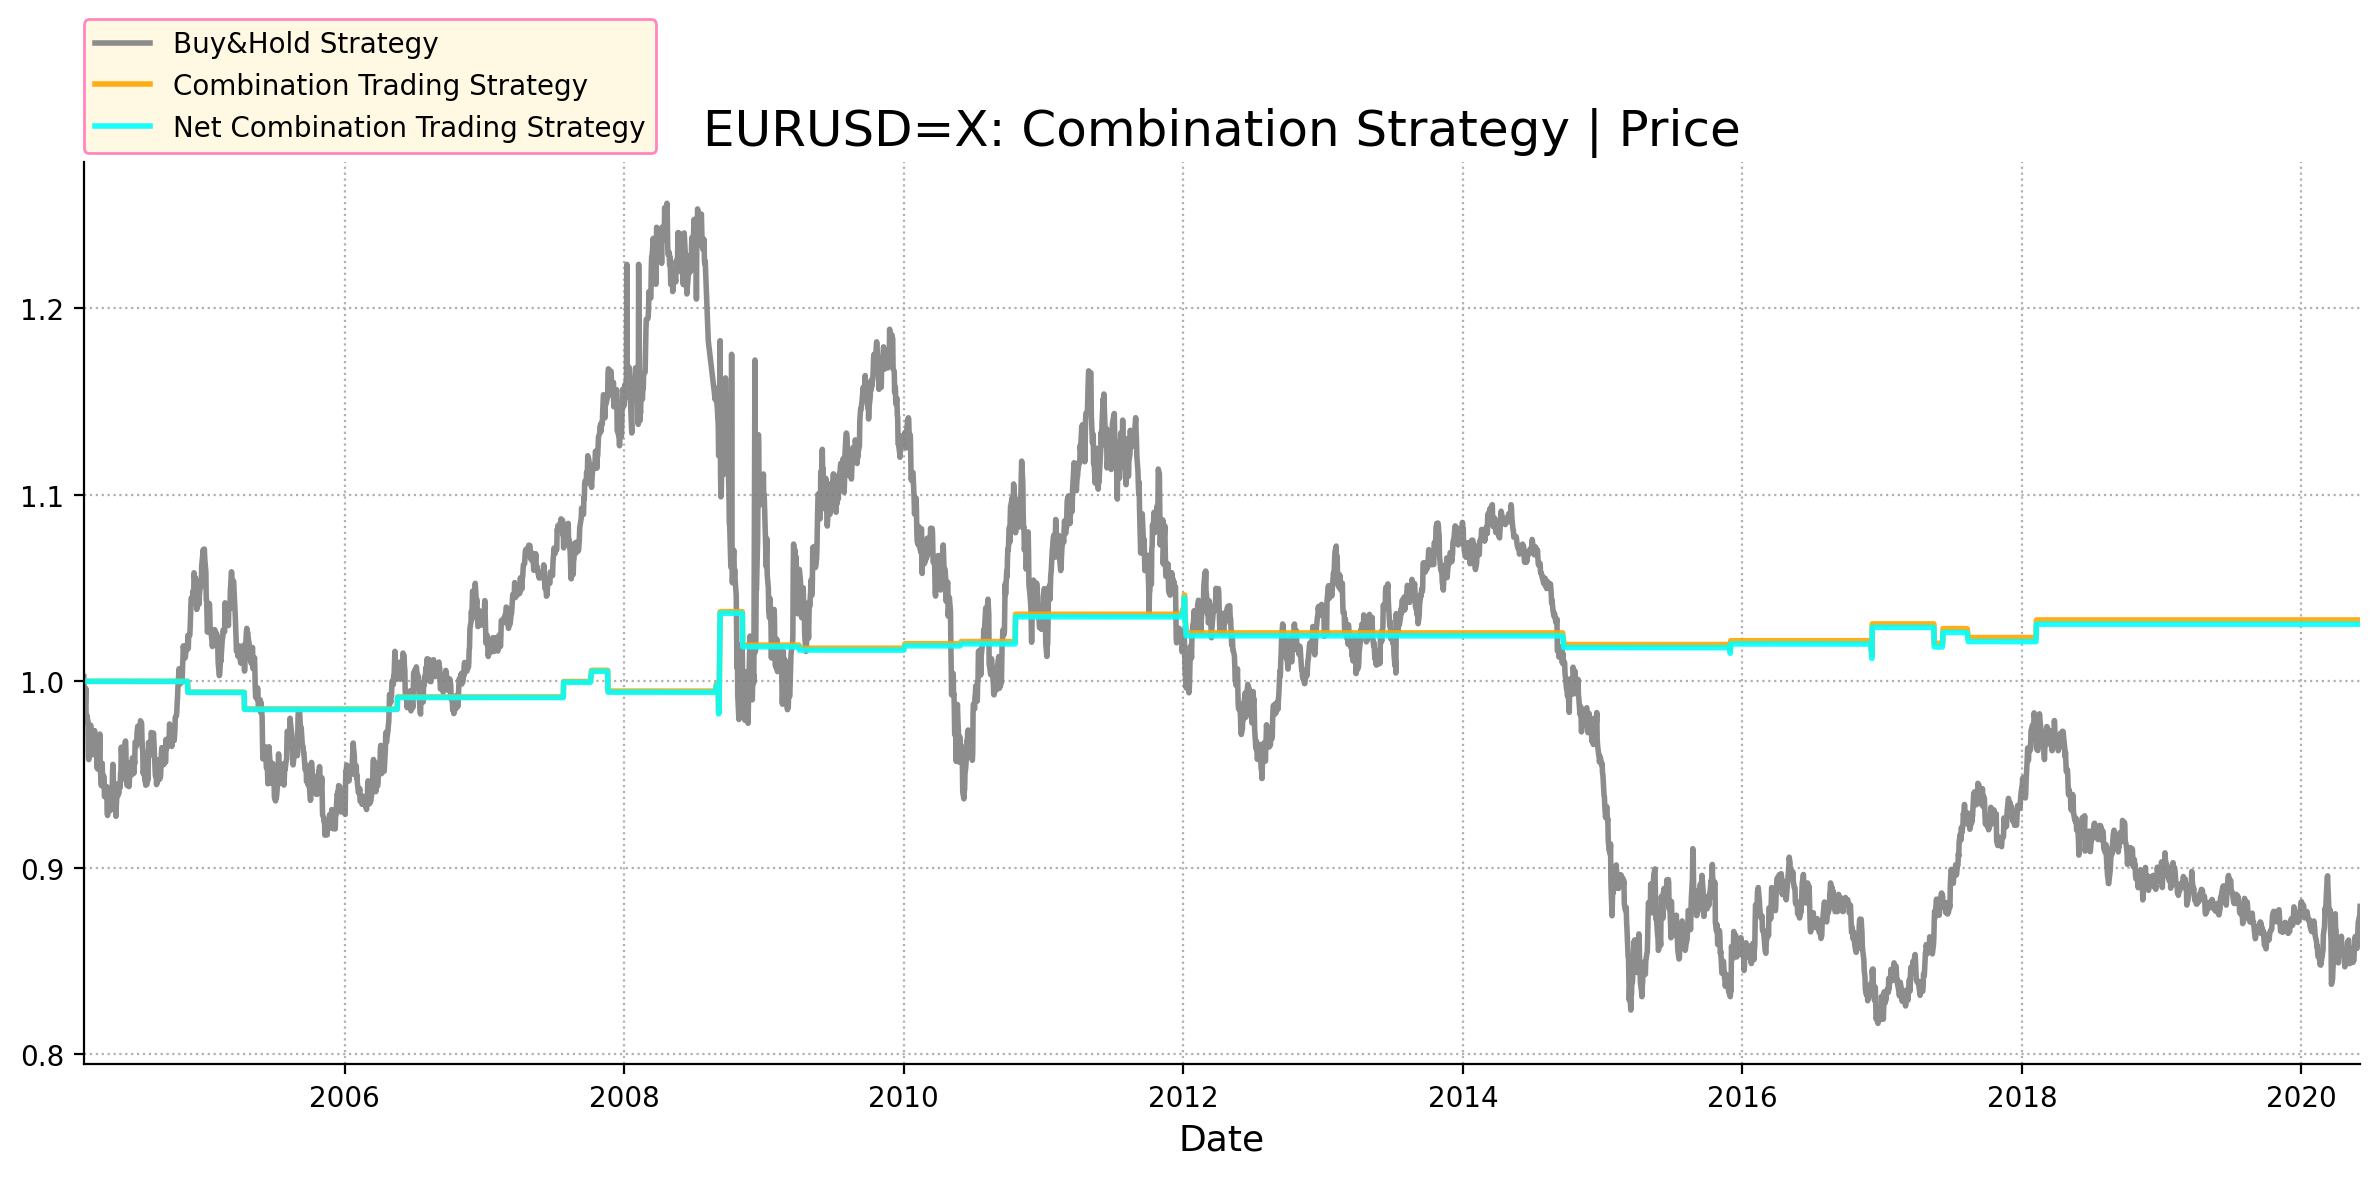

In [85]:
fig , ax = plt.subplots(figsize = (12,6))
ax.plot(df_combination.loc[:, ["cum_log_ret"]] , label = "Buy&Hold Strategy" , lw = 2 ,color = "gray" , alpha = .9)
ax.plot(df_combination.loc[:, ["cum_combination_strategy"]] , label = "Combination Trading Strategy" , lw = 2 ,color ="orange", alpha = .9)
ax.plot(df_combination.loc[:, ["cum_combination_net_strategy"]] , label = "Net Combination Trading Strategy" , lw = 2 ,color ="cyan", alpha = .9)
ax.spines[["right" , "top"]].set_visible(False)
ax.legend(loc = (0.,1.01) , fancybox = True , shadow = False , frameon = True , facecolor = "cornsilk" , edgecolor = "hotpink")
ax.autoscale(enable=True , axis ="x" , tight = True)
ax.set_xlabel("Date" , fontsize = 13)
ax.set_title(f"{symbol}: Combination Strategy | Price" , fontsize = 18)
ax.grid(ls = ":", lw= .8)

plt.tight_layout()
plt.show()